# EDA — Nhận dạng biểu cảm khuôn mặt (FER2013)

Bộ dữ liệu dùng trong bài là bản `msambare/fer2013` trên Kaggle (bản gốc của cuộc thi
*Challenges in Representation Learning: Facial Expression Recognition*), đã tách sẵn
thành hai thư mục `train/` và `test/`, mỗi thư mục có 7 thư mục con ứng với 7 biểu cảm.

Mục tiêu của notebook này là khảo sát dữ liệu trước khi xây mô hình: xem mỗi lớp có bao nhiêu
ảnh, ảnh trông thế nào, dữ liệu có cân bằng không. Từ đó mới quyết định cách chia tập, cách
đánh giá và có cần xử lý mất cân bằng hay không.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# Cố định seed để kết quả khảo sát lặp lại được
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Đường dẫn tương đối: chạy được cả từ thư mục notebooks/ lẫn từ gốc repo
HERE = Path.cwd()
ROOT = HERE if (HERE / "data").exists() else HERE.parent
DATA = ROOT / "data"
FIG = ROOT / "experiments" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Thứ tự lớp do ImageFolder sắp theo alphabet (KHÁC thứ tự 0..6 trong đề bài)
CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
TEN_VI = {
    "angry": "Giận",
    "disgust": "Ghê tởm",
    "fear": "Sợ hãi",
    "happy": "Vui",
    "neutral": "Bình thường",
    "sad": "Buồn",
    "surprise": "Ngạc nhiên",
}

# Font mặc định của matplotlib hỗ trợ tiếng Việt
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("Thư mục gốc :", ROOT)
print("Dữ liệu     :", DATA)
print("Hình lưu tại:", FIG)

Thư mục gốc : d:\workspace\DeepLearningDDU1231\Emotion_Recognition
Dữ liệu     : d:\workspace\DeepLearningDDU1231\Emotion_Recognition\data
Hình lưu tại: d:\workspace\DeepLearningDDU1231\Emotion_Recognition\experiments\figures


## 1. Đếm số ảnh của từng lớp

Trước hết ta kiểm tra cấu trúc thư mục và đếm số ảnh mỗi lớp ở hai tập `train` và `test`.
Chỉ cần đếm file nên bước này chạy rất nhanh, không phải đọc nội dung ảnh.

In [2]:
rows = []
for split in ["train", "test"]:
    for cls in CLASSES:
        n = len(list((DATA / split / cls).glob("*.jpg")))
        rows.append({"split": split, "class": cls, "ten_vi": TEN_VI[cls], "n": n})

df = pd.DataFrame(rows)
pivot = df.pivot(index="class", columns="split", values="n").loc[CLASSES]
pivot["tong"] = pivot.sum(axis=1)
pivot["ti_le_train_%"] = (pivot["train"] / pivot["train"].sum() * 100).round(2)

print("Tổng số ảnh:", pivot["tong"].sum())
pivot

Tổng số ảnh: 35887


split,test,train,tong,ti_le_train_%
class,,,,
angry,958,3995,4953,13.92
disgust,111,436,547,1.52
fear,1024,4097,5121,14.27
happy,1774,7215,8989,25.13
neutral,1233,4965,6198,17.29
sad,1247,4830,6077,16.82
surprise,831,3171,4002,11.05


Ta thấy tập train có gần 28.700 ảnh và test khoảng 7.200 ảnh, đúng bằng kích thước chuẩn của
FER2013. Điều đáng chú ý là số ảnh giữa các lớp chênh lệch rất lớn: `happy` nhiều nhất còn
`disgust` ít nhất, chỉ khoảng vài trăm ảnh. Phần sau sẽ xem tỉ lệ cụ thể.

## 2. Vẽ phân bố số ảnh theo lớp

Biểu đồ cột giúp nhìn nhanh mức độ mất cân bằng. Nếu một lớp quá ít mẫu thì mô hình rất dễ
bỏ qua lớp đó, nên ta cần biết trước để xử lý.

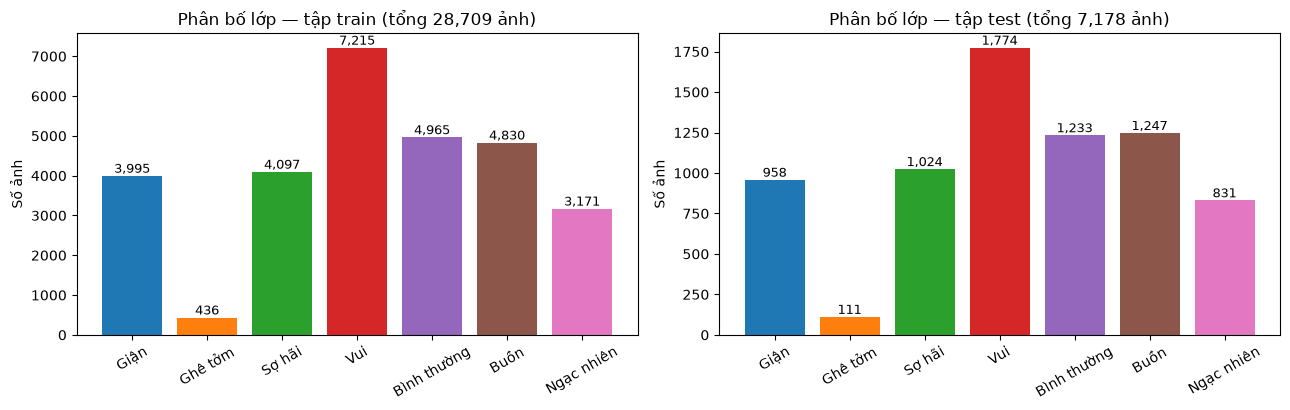

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

for ax, split in zip(axes, ["train", "test"]):
    values = pivot[split].values
    colors = plt.cm.tab10(np.arange(len(CLASSES)) / 10)
    bars = ax.bar([TEN_VI[c] for c in CLASSES], values, color=colors)
    ax.set_title(f"Phân bố lớp — tập {split} (tổng {values.sum():,} ảnh)")
    ax.set_ylabel("Số ảnh")
    ax.tick_params(axis="x", rotation=30)
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(FIG / "eda_01_phan_bo_lop.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Xem ảnh mẫu của từng lớp

Mỗi lớp ta lấy ngẫu nhiên 6 ảnh để biết dữ liệu trông như thế nào. Ảnh FER2013 chỉ 48×48 điểm
ảnh và là ảnh xám, nên nhìn sẽ khá mờ — đây cũng chính là lý do bài toán này khó.

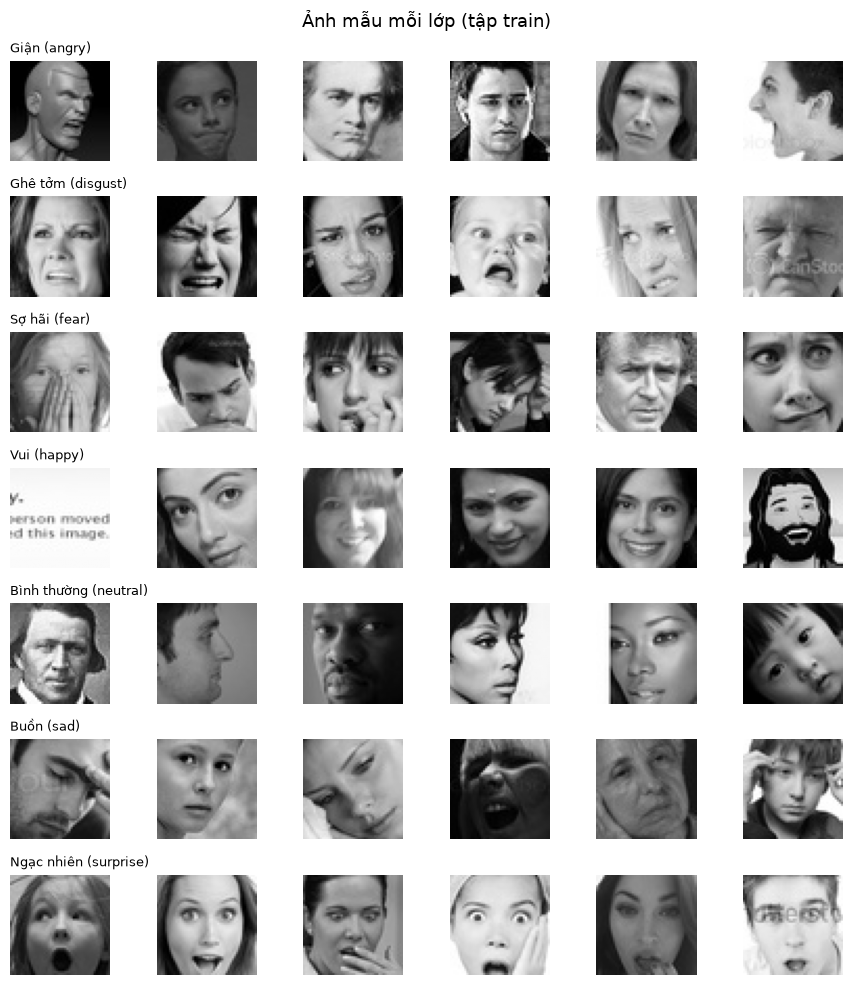

In [4]:
fig, axes = plt.subplots(7, 6, figsize=(9, 10))
rng = random.Random(SEED)

for i, cls in enumerate(CLASSES):
    files = sorted((DATA / "train" / cls).glob("*.jpg"))
    pick = rng.sample(files, 6)
    for j, f in enumerate(pick):
        ax = axes[i, j]
        ax.imshow(Image.open(f), cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
        if j == 0:
            ax.set_title(f"{TEN_VI[cls]} ({cls})", fontsize=9, loc="left")

plt.suptitle("Ảnh mẫu mỗi lớp (tập train)", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "eda_02_anh_mau.png", dpi=150, bbox_inches="tight")
plt.show()

Nhìn kỹ vào các ảnh mẫu sẽ thấy vài vấn đề của bộ dữ liệu gốc:

- Một số ảnh bị **dính chữ watermark** của trang web nguồn (thấy rõ ở dòng `Vui` góc trái).
- Có ảnh **không phải ảnh chụp thật** mà là tranh vẽ/ảnh chế, hoặc ảnh cắt rất sát mặt.
- Nhiều ảnh **nhãn có vẻ không khớp** với biểu cảm nhìn thấy, ví dụ dòng `Sợ hãi` có ảnh che mặt,
  dòng `Buồn` có ảnh đang nói chuyện.

Đây là nhiễu nhãn (label noise) cố hữu của FER2013 — dữ liệu được gán nhãn bán tự động. Điều
này giải thích vì sao độ chính xác trên bộ này thường bão hoà quanh 70% dù mô hình rất mạnh,
và cũng là lý do ta cần dùng regularization, dropout và early stopping thay vì cố học thật khít.

## 4. Kiểm tra kích thước và kiểu ảnh

Đề bài yêu cầu đầu vào 48×48. Ta kiểm tra ngẫu nhiên vài trăm ảnh xem có ảnh nào lệch kích
thước hay không màu hay không, để biết có phải resize lại không.

In [5]:
sample_files = []
rng = random.Random(SEED)
for cls in CLASSES:
    files = sorted((DATA / "train" / cls).glob("*.jpg"))
    sample_files += rng.sample(files, min(60, len(files)))

sizes, modes = set(), set()
for f in sample_files:
    with Image.open(f) as im:
        sizes.add(im.size)
        modes.add(im.mode)

print("Số ảnh kiểm tra:", len(sample_files))
print("Kích thước gặp phải:", sizes)
print("Kiểu màu gặp phải  :", modes)

Số ảnh kiểm tra: 420
Kích thước gặp phải: {(48, 48)}
Kiểu màu gặp phải  : {'L'}


Kết quả cho thấy mọi ảnh đều là 48×48 và ở chế độ xám (`L`), nên không cần bước resize hay đổi
màu. Khi nạp dữ liệu chỉ cần chuyển sang tensor 1 kênh là đủ.

## 5. Độ sáng và độ tương phản

Ta đo độ sáng trung bình và độ lệch chuẩn điểm ảnh trên một mẫu ngẫu nhiên. Nếu ảnh quá tối
hoặc tương phản thấp thì mô hình sẽ khó học đặc trưng, và việc chuẩn hoá đầu vào càng quan
trọng.

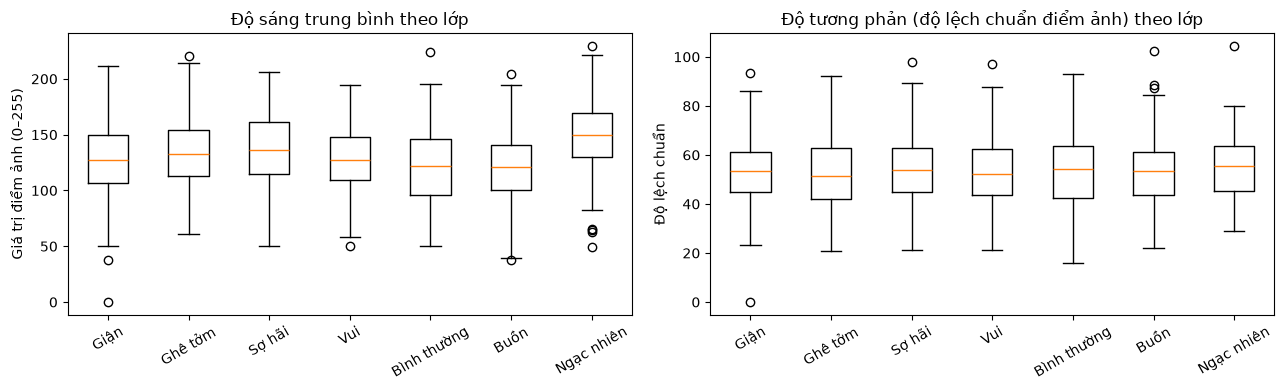

,do_sang_TB,tuong_phan_TB
Giận,126.599998,53.400002
Ghê tởm,135.300003,53.000000
Sợ hãi,135.300003,54.099998
Vui,128.500000,52.900002
Bình thường,121.500000,53.299999
Buồn,119.800003,53.700001
Ngạc nhiên,149.000000,54.799999


In [6]:
rng = random.Random(SEED)
bright_stat = {cls: [] for cls in CLASSES}
contrast_stat = {cls: [] for cls in CLASSES}

for cls in CLASSES:
    files = sorted((DATA / "train" / cls).glob("*.jpg"))
    for f in rng.sample(files, min(200, len(files))):
        arr = np.asarray(Image.open(f), dtype=np.float32)
        bright_stat[cls].append(arr.mean())
        contrast_stat[cls].append(arr.std())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot([bright_stat[c] for c in CLASSES], tick_labels=[TEN_VI[c] for c in CLASSES])
axes[0].set_title("Độ sáng trung bình theo lớp")
axes[0].set_ylabel("Giá trị điểm ảnh (0–255)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].boxplot([contrast_stat[c] for c in CLASSES], tick_labels=[TEN_VI[c] for c in CLASSES])
axes[1].set_title("Độ tương phản (độ lệch chuẩn điểm ảnh) theo lớp")
axes[1].set_ylabel("Độ lệch chuẩn")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(FIG / "eda_03_do_sang_tuong_phan.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(
    {
        "do_sang_TB": {TEN_VI[c]: np.mean(bright_stat[c]) for c in CLASSES},
        "tuong_phan_TB": {TEN_VI[c]: np.mean(contrast_stat[c]) for c in CLASSES},
    }
).round(1)

## 6. Mức độ mất cân bằng và trọng số lớp

Ta tính tỉ lệ số ảnh của lớp nhiều nhất so với lớp ít nhất, rồi thử công thức trọng số lớp
nghịch đảo tần suất:

$$w_c = \frac{N}{K \cdot n_c}$$

với $N$ là tổng số ảnh, $K$ là số lớp, $n_c$ là số ảnh của lớp $c$. Lớp càng ít mẫu thì trọng
số càng lớn, giúp mô hình không bỏ qua lớp hiếm khi tính hàm mất mát.

In [7]:
n_train = pivot["train"].values
K = len(CLASSES)
N = n_train.sum()

imbalance = n_train.max() / n_train.min()
weights = N / (K * n_train)

print(f"Lớp nhiều nhất: {TEN_VI[CLASSES[n_train.argmax()]]} ({n_train.max():,} ảnh)")
print(f"Lớp ít nhất   : {TEN_VI[CLASSES[n_train.argmin()]]} ({n_train.min():,} ảnh)")
print(f"Tỉ lệ mất cân bằng: {imbalance:.1f} lần")
print()
pd.DataFrame(
    {
        "class": CLASSES,
        "so_anh": n_train,
        "ti_le_%": (n_train / N * 100).round(2),
        "trong_so": weights.round(3),
    }
)

Lớp nhiều nhất: Vui (7,215 ảnh)
Lớp ít nhất   : Ghê tởm (436 ảnh)
Tỉ lệ mất cân bằng: 16.5 lần



,class,so_anh,ti_le_%,trong_so
0,angry,3995,13.92,1.027
1,disgust,436,1.52,9.407
2,fear,4097,14.27,1.001
3,happy,7215,25.13,0.568
4,neutral,4965,17.29,0.826
5,sad,4830,16.82,0.849
6,surprise,3171,11.05,1.293


## 7. Nhận xét tổng hợp

Từ các khảo sát trên, em rút ra mấy điểm sẽ ảnh hưởng trực tiếp đến phần xây mô hình:

1. **Dữ liệu đúng chuẩn đề bài**: 28.709 ảnh train, 7.178 ảnh test, tất cả 48×48 grayscale,
   7 lớp đúng như mô tả. Không cần bước resize hay tiền xử lý màu.
2. **Mất cân bằng mạnh**: lớp `disgust` chỉ có 436 ảnh (1,5%) trong khi `happy` có 7.215 ảnh
   (25,1%), chênh khoảng 16,5 lần. Vì vậy nếu chỉ nhìn accuracy thì con số có thể bị "đẹp giả":
   một mô hình đoán bừa lớp `happy` cũng đã được khoảng 25%. Do đó khi đánh giá phải xem thêm
   F1 từng lớp và confusion matrix.
3. **Ảnh rất nhỏ và mờ**: 48×48 khiến các chi tiết như lông mày, khoé miệng chỉ còn vài điểm
   ảnh. Ba lớp dễ lẫn nhau nhất thường là `fear` – `sad` – `neutral`, còn `disgust` thì ít mẫu
   nên càng khó.
4. **Dữ liệu có nhiễu nhãn**: như quan sát ở mục 3, có ảnh dính watermark, ảnh tranh vẽ, và một
   số ảnh nhãn không khớp biểu cảm. Vì vậy không nên kỳ vọng vượt xa mốc 69–71% của cuộc thi, và
   việc đánh giá cần nhìn cả các mẫu dự đoán sai chứ không chỉ một con số accuracy.
5. **Ảnh hơi tối, tương phản trung bình**: độ sáng trung vị khoảng 125–165/255 tuỳ lớp, độ lệch
   chuẩn khoảng 50, nên cần chuẩn hoá đầu vào (trừ trung bình, chia độ lệch chuẩn) để việc huấn
   luyện ổn định hơn.
6. **Cách chia tập**: sẽ giữ nguyên `test/` làm tập đánh giá cuối (chỉ chạm một lần), còn từ
   `train/` tách stratified 10% làm validation để chọn siêu tham số. Vì dữ liệu lệch lớp nên
   phải chia theo tỉ lệ từng lớp, nếu chia ngẫu nhiên thuần thì lớp hiếm có thể rơi hết vào một
   phía.
7. **Có thể dùng class weight** như công thức ở mục 6 khi huấn luyện, và sẽ thử so sánh có/không
   dùng trong phần thí nghiệm thay vì mặc định là tốt hơn.